In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit
df = pd.read_csv('../data/diabetic_data.csv')
df.head()
df.isnull().sum()

encounter_id                    0
patient_nbr                     0
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          0
diag_2                          0
diag_3                          0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

# 1. Load Data
df = pd.read_csv('../data/diabetic_data.csv')

# 2. Filter Ineligible Patients (Dead/Hospice)
# IDS codes 11, 13, 14, 19, 20, 21 represent expired or hospice patients
dead_hospice_ids = [11, 13, 14, 19, 20, 21]
df_clean = df[~df['discharge_disposition_id'].isin(dead_hospice_ids)].copy()

# 3. Create Binary Target
# 1 = Readmitted in <30 days, 0 = Not readmitted
df_clean['target'] = (df_clean['readmitted'] == '<30').astype(int)

# 4. Standardize Missing Values ('?' to NaN)
df_clean.replace('?', np.nan, inplace=True)

# Drop columns with extreme missingness or low value
df_clean = df_clean.drop(columns=['weight', 'payer_code', 'medical_specialty', 'encounter_id'])

# 5. Patient-Level Train/Test Split (Leakage Prevention)
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_idx, test_idx = next(gss.split(df_clean, groups=df_clean['patient_nbr']))

train_df = df_clean.iloc[train_idx].copy()
test_df = df_clean.iloc[test_idx].copy()

print(f"Original Data: {df.shape[0]} encounters")
print(f"Cleaned Data (Ineligible Removed): {df_clean.shape[0]} encounters")
print(f"Training Set: {train_df.shape[0]} encounters | Readmission Rate: {train_df['target'].mean():.3f}")
print(f"Testing Set: {test_df.shape[0]} encounters | Readmission Rate: {test_df['target'].mean():.3f}")

Original Data: 101766 encounters
Cleaned Data (Ineligible Removed): 99343 encounters
Training Set: 79541 encounters | Readmission Rate: 0.114
Testing Set: 19802 encounters | Readmission Rate: 0.112


In [21]:
# --- STEP 2: FEATURE ENGINEERING ---

def map_icd9_to_category(val):
    """Maps raw ICD-9 codes to 9 core clinical categories (Strack et al.)."""
    if pd.isna(val) or val == '?':
        return 'Missing'
    
    val = str(val).strip()
    
    # Supplemental classifications
    if val.startswith('V') or val.startswith('E'):
        return 'Other'
    
    try:
        code = float(val)
    except ValueError:
        return 'Other'
    
    # Standard Medical Grouping
    if (390 <= code <= 459) or code == 785:
        return 'Circulatory'
    elif (460 <= code <= 519) or code == 786:
        return 'Respiratory'
    elif (520 <= code <= 579) or code == 787:
        return 'Digestive'
    elif int(code) == 250:
        return 'Diabetes'
    elif (800 <= code <= 999):
        return 'Injury'
    elif (710 <= code <= 739):
        return 'Musculoskeletal'
    elif (580 <= code <= 629) or code == 788:
        return 'Genitourinary'
    elif (140 <= code <= 239):
        return 'Neoplasms'
    else:
        return 'Other'

# 1. Apply Clinical Grouping to Diagnoses (Dimensionality Reduction)
for col in ['diag_1', 'diag_2', 'diag_3']:
    # We apply this to both train and test sets to maintain consistency
    train_df[col] = train_df[col].apply(map_icd9_to_category)
    test_df[col] = test_df[col].apply(map_icd9_to_category)

# 2. Engineer Historical Utilization Features
train_df['total_historical_visits'] = train_df['number_outpatient'] + train_df['number_emergency'] + train_df['number_inpatient']
test_df['total_historical_visits'] = test_df['number_outpatient'] + test_df['number_emergency'] + test_df['number_inpatient']

# 3. Create a Medical Complexity Flag (Patient has 5 or more diagnoses recorded)
train_df['complex_patient'] = (train_df['number_diagnoses'] >= 5).astype(int)
test_df['complex_patient'] = (test_df['number_diagnoses'] >= 5).astype(int)

print("Feature Engineering Complete.")
print("\nDistribution of mapped Primary Diagnoses (diag_1) in Training Data:")
print(train_df['diag_1'].value_counts())
print(f"\nEngineered Features Added: total_historical_visits, complex_patient")


Feature Engineering Complete.

Distribution of mapped Primary Diagnoses (diag_1) in Training Data:
diag_1
Circulatory        23739
Other              14182
Respiratory        11225
Digestive           7487
Diabetes            6930
Injury              5475
Genitourinary       4000
Musculoskeletal     3972
Neoplasms           2516
Missing               15
Name: count, dtype: int64

Engineered Features Added: total_historical_visits, complex_patient


In [22]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
import pandas as pd
import numpy as np

# 1. Load the main dataset
df = pd.read_csv('../data/diabetic_data.csv')

# 2. Parse the stacked IDS_mapping_2.csv file
# We read it in, and then carefully split it into three separate lookup dictionaries
with open('../data/IDS_mapping.csv', 'r') as f:
    mapping_content = f.read().split('\n')

admission_type_map = {}
discharge_disposition_map = {}
admission_source_map = {}

current_map = None

for line in mapping_content:
    if 'admission_type_id' in line:
        current_map = admission_type_map
        continue
    elif 'discharge_disposition_id' in line:
        current_map = discharge_disposition_map
        continue
    elif 'admission_source_id' in line:
        current_map = admission_source_map
        continue
    
    # Skip empty lines or malformed rows
    if not line.strip() or ',' not in line:
        continue
        
    try:
        # Split only on the first comma to preserve descriptions with commas
        key, value = line.split(',', 1)
        # Clean up quotes and missing data representations
        value = value.replace('"', '').strip()
        if value.lower() in ['nan', 'not mapped', 'not available', '?', '']:
            value = np.nan
        current_map[int(key)] = value
    except ValueError:
        continue

# 3. Map the extracted dictionaries to the main dataset
# We create new columns with the text descriptions for better EDA readability
df['admission_type_desc'] = df['admission_type_id'].map(admission_type_map)
df['discharge_disposition_desc'] = df['discharge_disposition_id'].map(discharge_disposition_map)
df['admission_source_desc'] = df['admission_source_id'].map(admission_source_map)

# 4. View the successfully merged data
print("Merge Complete! Here is a sample of the mapped columns:")
display_cols = [
    'admission_type_id', 'admission_type_desc', 
    'discharge_disposition_id', 'discharge_disposition_desc'
]
print(df[display_cols].head())

Merge Complete! Here is a sample of the mapped columns:
   admission_type_id admission_type_desc  discharge_disposition_id  \
0                  6                NULL                        25   
1                  1           Emergency                         1   
2                  1           Emergency                         1   
3                  1           Emergency                         1   
4                  1           Emergency                         1   

  discharge_disposition_desc  
0                        NaN  
1         Discharged to home  
2         Discharged to home  
3         Discharged to home  
4         Discharged to home  


/var/folders/1s/tkyy_34501sflqqvs9m_8_rw0000gn/T/ipykernel_74260/473858169.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_df['Missing %'], y=missing_df.index, palette='viridis')


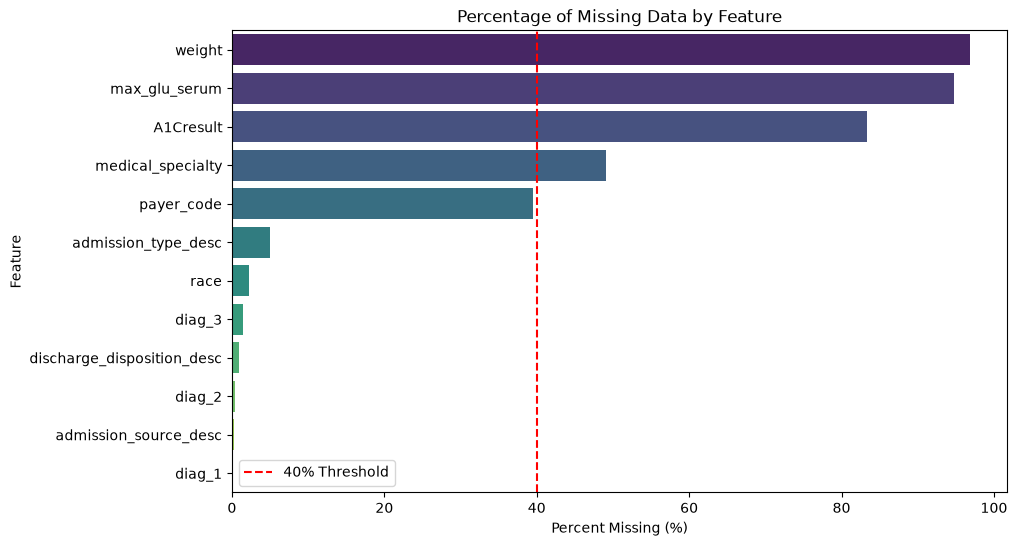

                            Missing Count  Missing %
weight                              98569  96.858479
max_glu_serum                       96420  94.746772
A1Cresult                           84748  83.277322
medical_specialty                   49949  49.082208
payer_code                          40256  39.557416
admission_type_desc                  5105   5.016410
race                                 2273   2.233555
diag_3                               1423   1.398306
discharge_disposition_desc            989   0.971837
diag_2                                358   0.351787
admission_source_desc                 286   0.281037
diag_1                                 21   0.020636


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Load data and standardize missing values
df.replace('?', np.nan, inplace=True)

# Calculate missing percentages
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_percent})
missing_df = missing_df[missing_df['Missing %'] > 0].sort_values(by='Missing %', ascending=False)

# Plot missingness
plt.figure(figsize=(10, 6))
sns.barplot(x=missing_df['Missing %'], y=missing_df.index, palette='viridis')
plt.title('Percentage of Missing Data by Feature')
plt.xlabel('Percent Missing (%)')
plt.ylabel('Feature')
plt.axvline(x=40, color='red', linestyle='--', label='40% Threshold')
plt.legend()
plt.show()

print(missing_df)


/var/folders/1s/tkyy_34501sflqqvs9m_8_rw0000gn/T/ipykernel_74260/577111457.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='readmitted', data=df, palette='Set2', order=['NO', '>30', '<30'], ax=axes[0])


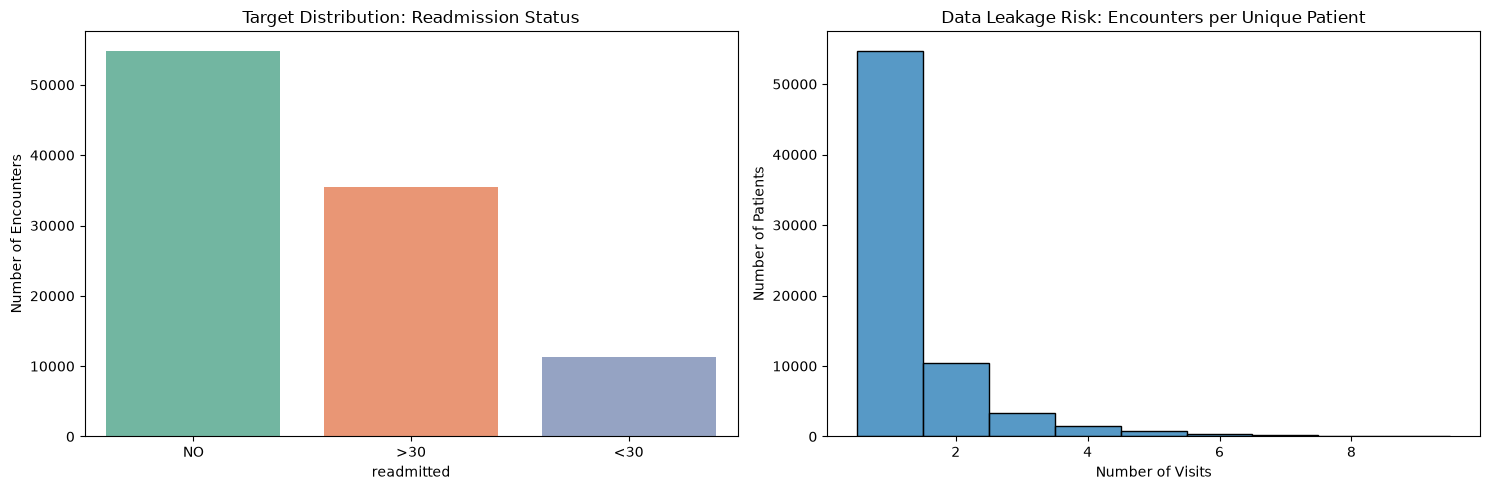

Total Encounters: 101766
Unique Patients: 71518
Target <30 class proportion: 11.16%


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Target Imbalance
sns.countplot(x='readmitted', data=df, palette='Set2', order=['NO', '>30', '<30'], ax=axes[0])
axes[0].set_title('Target Distribution: Readmission Status')
axes[0].set_ylabel('Number of Encounters')

# Plot 2: Patient Leakage Check (Encounters per Patient)
encounters_per_patient = df['patient_nbr'].value_counts()
sns.histplot(encounters_per_patient[encounters_per_patient < 10], bins=9, discrete=True, ax=axes[1])
axes[1].set_title('Data Leakage Risk: Encounters per Unique Patient')
axes[1].set_xlabel('Number of Visits')
axes[1].set_ylabel('Number of Patients')

plt.tight_layout()
plt.show()

print(f"Total Encounters: {len(df)}")
print(f"Unique Patients: {df['patient_nbr'].nunique()}")
print(f"Target <30 class proportion: {(df['readmitted'] == '<30').mean() * 100:.2f}%")


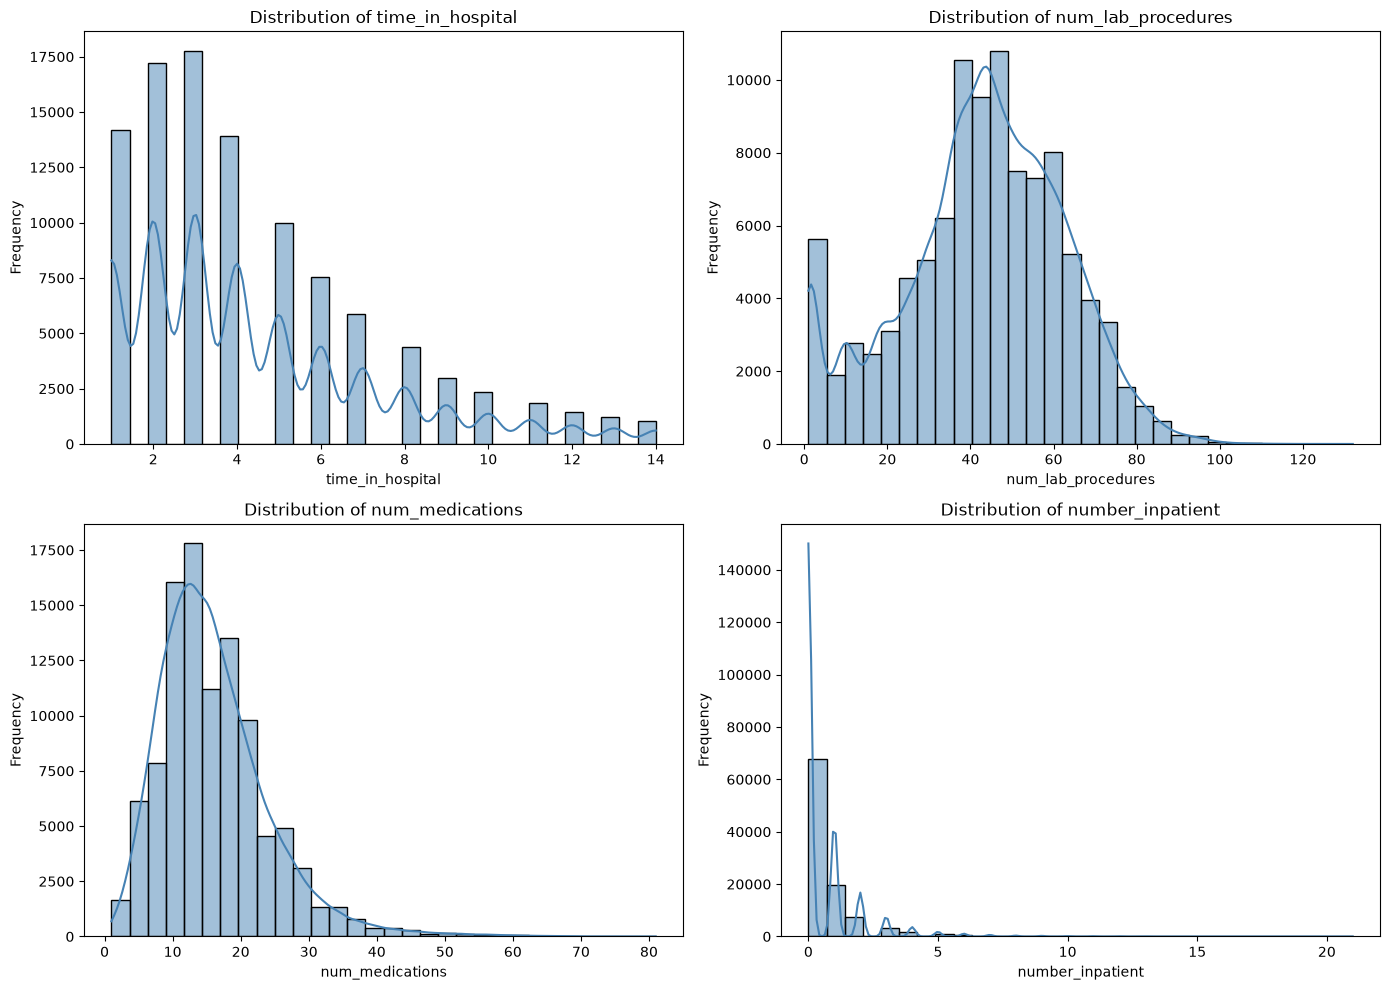

       time_in_hospital  num_lab_procedures  num_medications  number_inpatient
count     101766.000000       101766.000000    101766.000000     101766.000000
mean           4.395987           43.095641        16.021844          0.635566
std            2.985108           19.674362         8.127566          1.262863
min            1.000000            1.000000         1.000000          0.000000
25%            2.000000           31.000000        10.000000          0.000000
50%            4.000000           44.000000        15.000000          0.000000
75%            6.000000           57.000000        20.000000          1.000000
max           14.000000          132.000000        81.000000         21.000000


In [26]:
# Select numerical columns of interest
num_cols = ['time_in_hospital', 'num_lab_procedures', 'num_medications', 'number_inpatient']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

print(df[num_cols].describe())


/var/folders/1s/tkyy_34501sflqqvs9m_8_rw0000gn/T/ipykernel_74260/1086539833.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='metformin', y='temp_target_30d', data=df, order=['No', 'Steady', 'Down', 'Up'], errorbar=None, palette='coolwarm')


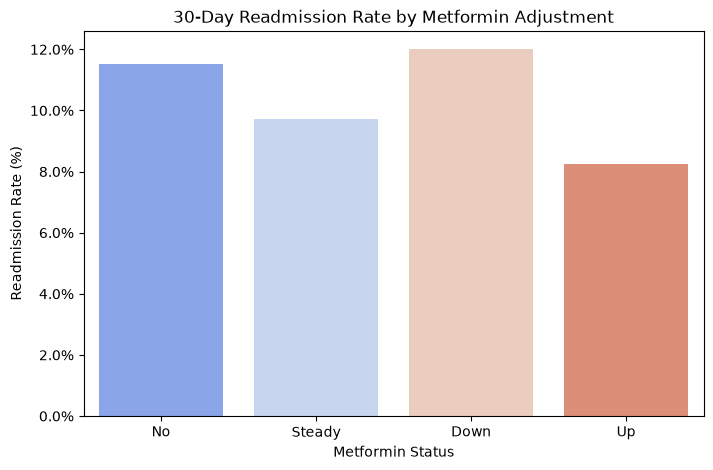

In [27]:
# Create temporary binary target for visualization
df['temp_target_30d'] = (df['readmitted'] == '<30').astype(int)

# Focus on the most common medication: Metformin
plt.figure(figsize=(8, 5))
sns.barplot(x='metformin', y='temp_target_30d', data=df, order=['No', 'Steady', 'Down', 'Up'], errorbar=None, palette='coolwarm')
plt.title('30-Day Readmission Rate by Metformin Adjustment')
plt.ylabel('Readmission Rate (%)')
plt.xlabel('Metformin Status')
# Convert y-axis to percentages
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.1%}'.format(y)))
plt.show()


In [28]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
import xgboost as xgb

# --- PHASE 2: CUSTOM TRANSFORMATIONS (Functional Approach) ---

# We define the ICD-9 mapping logic from Strack et al.
def map_icd9_to_category(val):
    if pd.isna(val): return 'Missing'
    val = str(val).strip()
    if val.startswith('V') or val.startswith('E'): return 'Other'
    try:
        code = float(val)
        if (390 <= code <= 459) or code == 785: return 'Circulatory'
        elif (460 <= code <= 519) or code == 786: return 'Respiratory'
        elif (520 <= code <= 579) or code == 787: return 'Digestive'
        elif int(code) == 250: return 'Diabetes'
        elif (800 <= code <= 999): return 'Injury'
        elif (710 <= code <= 739): return 'Musculoskeletal'
        elif (580 <= code <= 629) or code == 788: return 'Genitourinary'
        elif (140 <= code <= 239): return 'Neoplasms'
        else: return 'Other'
    except ValueError:
        return 'Other'

# Apply transformations directly to df_clean (which already has ineligible dropped and target created)
for col in ['diag_1', 'diag_2', 'diag_3']:
    df_clean[col] = df_clean[col].apply(map_icd9_to_category)

df_clean['total_historical_visits'] = df_clean['number_outpatient'] + df_clean['number_emergency'] + df_clean['number_inpatient']
df_clean['complex_patient'] = (df_clean['number_diagnoses'] >= 5).astype(int)

# --- PHASE 3: THE PREPROCESSING PIPELINE ---

# 1. Define Feature Categories
# Ordinal features represent clinical progression (rank matters)
ordinal_features = [
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 
    'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 
    'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 
    'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 
    'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 
    'change', 'diabetesMed'
]

# Nominal features represent unordered categories
nominal_features = ['race', 'gender', 'age', 'diag_1', 'diag_2', 'diag_3', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id']

# Numerical features
numeric_features = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_diagnoses', 'total_historical_visits', 'complex_patient']

# 2. Define the Transformers
# Meds order: No < Steady < Down < Up. Change order: No < Ch. Med order: No < Yes.
med_categories = [['No', 'Steady', 'Down', 'Up']] * 23
change_categories = [['No', 'Ch']]
diab_med_categories = [['No', 'Yes']]
ordinal_categories = med_categories + change_categories + diab_med_categories

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()) # Standardizing helps if you ever switch to Logistic Regression/NNs
])

ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=ordinal_categories, handle_unknown='use_encoded_value', unknown_value=-1))
])

nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    # drop='first' prevents multicollinearity issues
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first')) 
])

# 3. Combine into a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('ord', ordinal_transformer, ordinal_features),
        ('nom', nominal_transformer, nominal_features)
    ],
    remainder='drop' # Drop anything not explicitly specified
)

# 4. Leakage-Proof Split & Pipeline Execution
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_idx, test_idx = next(gss.split(df_clean, groups=df_clean['patient_nbr']))

X_train = df_clean.iloc[train_idx].drop(columns=['target', 'readmitted'])
y_train = df_clean.iloc[train_idx]['target']

X_test = df_clean.iloc[test_idx].drop(columns=['target', 'readmitted'])
y_test = df_clean.iloc[test_idx]['target']

# Fit the preprocessor on Train, and ONLY transform Test
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Pipeline Execution Complete.")
print(f"Processed Training Features Shape: {X_train_processed.shape}")
print(f"Processed Testing Features Shape: {X_test_processed.shape}")


Pipeline Execution Complete.
Processed Training Features Shape: (79541, 117)
Processed Testing Features Shape: (19802, 117)


Calculated scale_pos_weight to handle 11% imbalance: 7.74
Training XGBoost model. This may take a minute...
------------------------------
XGBoost PR-AUC:   0.2152
XGBoost F1-Score: 0.2659
------------------------------

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.65      0.77     17586
           1       0.17      0.58      0.27      2216

    accuracy                           0.64     19802
   macro avg       0.55      0.61      0.52     19802
weighted avg       0.84      0.64      0.71     19802



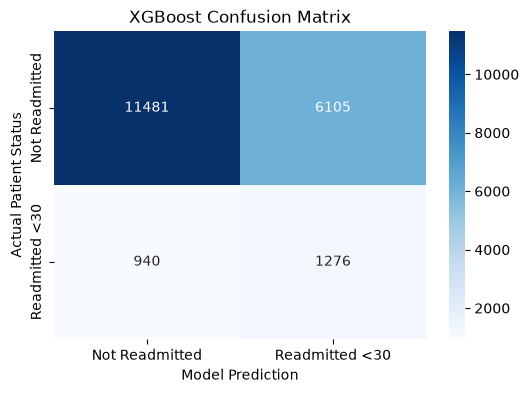

In [29]:
import xgboost as xgb
from sklearn.metrics import precision_recall_curve, auc, f1_score, classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate the scale_pos_weight
# XGBoost uses this formula to mathematically penalize the model heavily 
# when it misses the minority class (readmissions).
# Formula: Count(Negative Class) / Count(Positive Class)
scale_pos_weight = (len(y_train) - y_train.sum()) / y_train.sum()
print(f"Calculated scale_pos_weight to handle 11% imbalance: {scale_pos_weight:.2f}")

# 2. Initialize the XGBoost Classifier
# We use objective='binary:logistic' to output probability scores (0.0 to 1.0)
# which are required for your Top-K Threshold Optimization later.
xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',
    scale_pos_weight=scale_pos_weight,
    n_estimators=150,
    max_depth=4,         # Kept shallow to prevent overfitting on clinical data
    learning_rate=0.1,
    random_state=42,
    eval_metric='aucpr', # Tell XGBoost to optimize for PR-AUC internally
    n_jobs=-1
)

# 3. Train the Model
print("Training XGBoost model. This may take a minute...")
xgb_model.fit(X_train_processed, y_train)

# 4. Generate Predictions (Both absolute classes and probabilities)
y_pred = xgb_model.predict(X_test_processed)
y_proba = xgb_model.predict_proba(X_test_processed)[:, 1] # Probability of Class 1 (<30)

# 5. Evaluate using the specific metrics from your project
# Calculate PR-AUC
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
pr_auc = auc(recall, precision)
f1 = f1_score(y_test, y_pred)

print("-" * 30)
print(f"XGBoost PR-AUC:   {pr_auc:.4f}")
print(f"XGBoost F1-Score: {f1:.4f}")
print("-" * 30)

# Print the detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 6. Visualize the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Not Readmitted', 'Readmitted <30'], 
            yticklabels=['Not Readmitted', 'Readmitted <30'])
plt.title('XGBoost Confusion Matrix')
plt.ylabel('Actual Patient Status')
plt.xlabel('Model Prediction')
plt.show()


Hospital Intervention Capacity (Top-K): 990 patients
Optimized Probability Threshold for Top-990: 0.6905
----------------------------------------
Top-K Precision (Intervention Accuracy): 30.0%
Top-K Recall (Readmissions Prevented):   13.4%
----------------------------------------


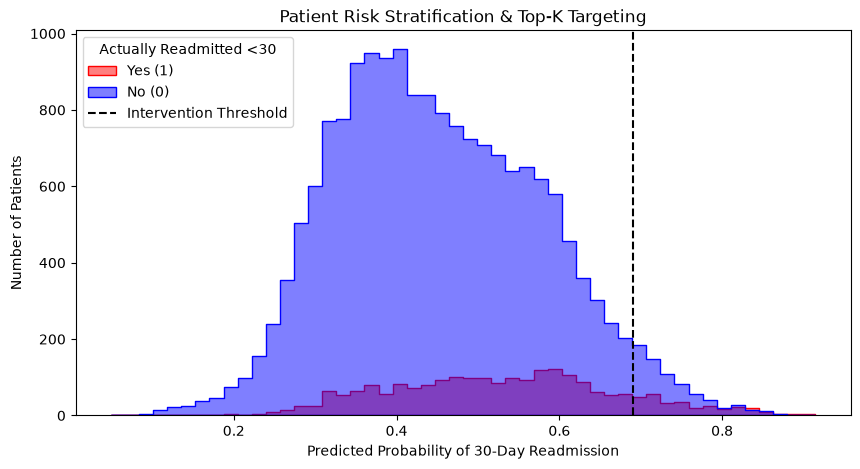

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score

# 1. Define Hospital Capacity (The 'K' in Top-K)
# Let's assume the hospital can only intervene on 5% of patients in this test period
K_capacity = int(len(y_test) * 0.05) 
print(f"Hospital Intervention Capacity (Top-K): {K_capacity} patients")

# 2. Create a Risk Registry DataFrame
# We combine the actual outcomes with the model's predicted probabilities
risk_df = pd.DataFrame({
    'Actual_Readmitted': y_test.values,
    'Risk_Score_Probability': y_proba
})

# Sort patients from highest risk to lowest risk
risk_df = risk_df.sort_values(by='Risk_Score_Probability', ascending=False).reset_index(drop=True)

# 3. Apply Top-K Thresholding
# Identify the exact probability threshold that isolates our Top K patients
optimized_threshold = risk_df.loc[K_capacity - 1, 'Risk_Score_Probability']
print(f"Optimized Probability Threshold for Top-{K_capacity}: {optimized_threshold:.4f}")

# Generate new predictions based purely on this customized threshold
risk_df['Top_K_Intervention'] = (risk_df['Risk_Score_Probability'] >= optimized_threshold).astype(int)

# 4. Evaluate the Operational Impact
top_k_precision = precision_score(risk_df['Actual_Readmitted'], risk_df['Top_K_Intervention'])
# Recall represents the percentage of TOTAL readmissions we caught within our limited Top-K budget
top_k_recall = risk_df[risk_df['Top_K_Intervention'] == 1]['Actual_Readmitted'].sum() / risk_df['Actual_Readmitted'].sum()

print("-" * 40)
print(f"Top-K Precision (Intervention Accuracy): {top_k_precision:.1%}")
print(f"Top-K Recall (Readmissions Prevented):   {top_k_recall:.1%}")
print("-" * 40)

# 5. Visualize the Risk Stratification
plt.figure(figsize=(10, 5))
sns.histplot(data=risk_df, x='Risk_Score_Probability', hue='Actual_Readmitted', 
             bins=50, element="step", common_norm=False, palette={0: 'blue', 1: 'red'}, alpha=0.5)
plt.axvline(x=optimized_threshold, color='black', linestyle='--', 
            label=f'Top-{K_capacity} Threshold ({optimized_threshold:.2f})')
plt.title('Patient Risk Stratification & Top-K Targeting')
plt.xlabel('Predicted Probability of 30-Day Readmission')
plt.ylabel('Number of Patients')
plt.legend(title='Actually Readmitted <30', labels=['Yes (1)', 'No (0)', 'Intervention Threshold'])
plt.show()


In [31]:
!pip install shap


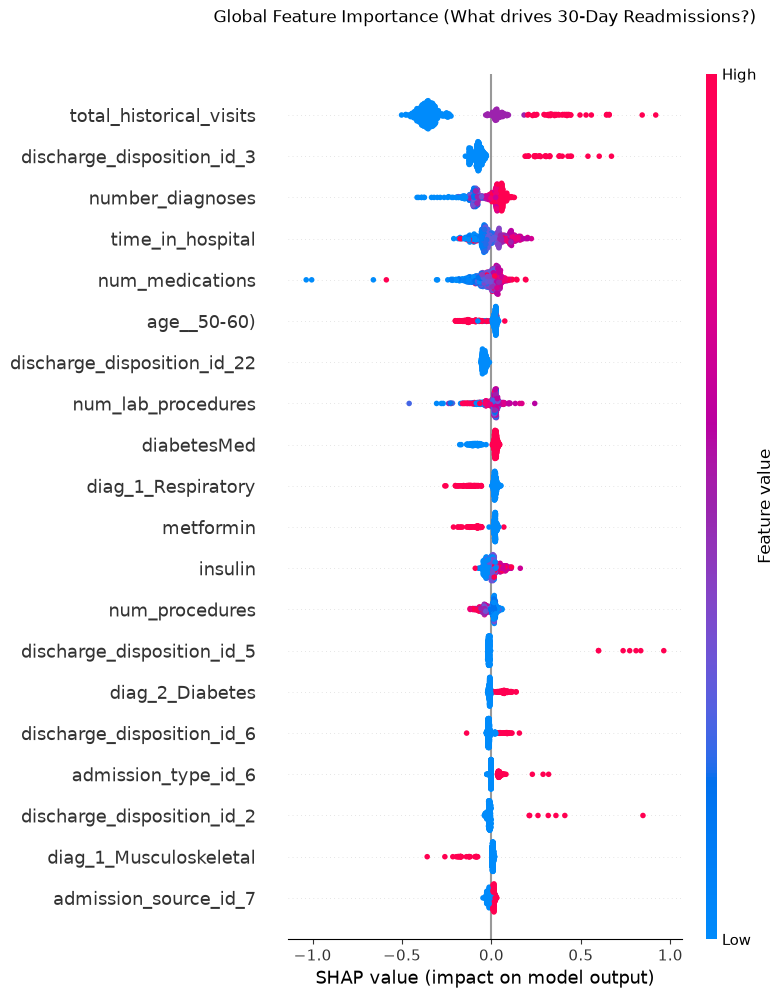


Analyzing Patient Index 245
Model Predicted Readmission Probability: 75.7%


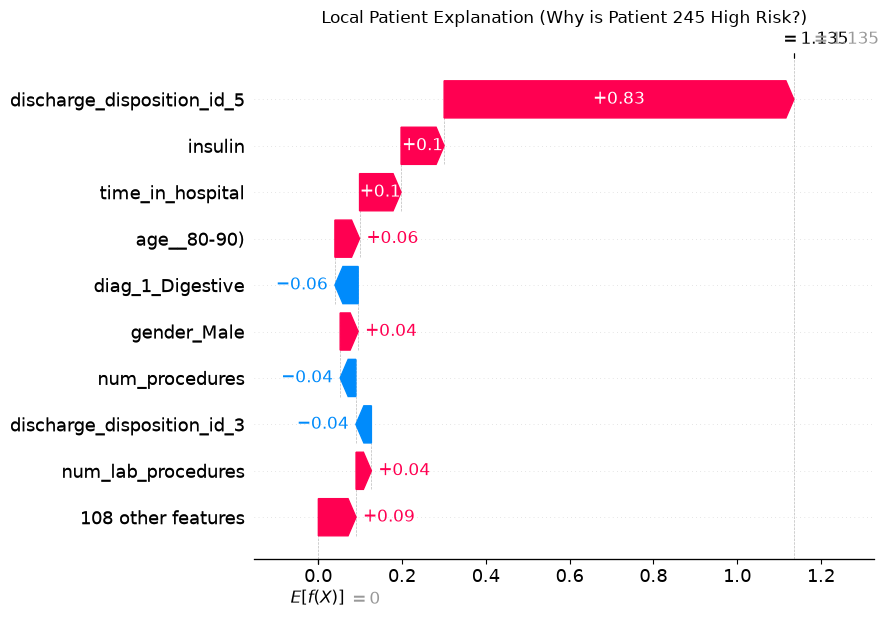

In [40]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# 1. Initialize the SHAP Tree Explainer
explainer = shap.TreeExplainer(xgb_model)

# 2. Extract feature names from your pipeline's preprocessor
num_cols = numeric_features
ord_cols = ordinal_features
nom_cols = preprocessor.named_transformers_['nom'].named_steps['encoder'].get_feature_names_out(nominal_features).tolist()
all_feature_names = num_cols + ord_cols + nom_cols

# 3. Sanitize the feature names to remove [, ], and <
clean_feature_names = [re.sub(r'[\[\]<]', '_', name) for name in all_feature_names]

# 4. Prepare the sample data using the cleaned names
X_test_sample = pd.DataFrame(X_test_processed[:500], columns=clean_feature_names)
shap_values = explainer.shap_values(X_test_sample)

# --- GLOBAL INTERPRETABILITY ---
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.title("Global Feature Importance (What drives 30-Day Readmissions?)", y=1.05)
plt.show()

# --- LOCAL INTERPRETABILITY (Patient-Level) ---
patient_predictions = xgb_model.predict_proba(X_test_sample)[:, 1]
high_risk_index = np.argmax(patient_predictions)

print(f"\nAnalyzing Patient Index {high_risk_index}")
print(f"Model Predicted Readmission Probability: {patient_predictions[high_risk_index]:.1%}")

plt.figure(figsize=(8, 5))
shap.plots._waterfall.waterfall_legacy(explainer.expected_value, 
                                       shap_values[high_risk_index], 
                                       feature_names=X_test_sample.columns, 
                                       max_display=10, 
                                       show=False)
plt.title(f"Local Patient Explanation (Why is Patient {high_risk_index} High Risk?)")
plt.show()


In [37]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,admission_type_desc,discharge_disposition_desc,admission_source_desc,temp_target_30d
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,NO,NULL,NaN,Physician Referral,0
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,No,No,Ch,Yes,>30,Emergency,Discharged to home,Emergency Room,0
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,Yes,NO,Emergency,Discharged to home,Emergency Room,0
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,No,No,Ch,Yes,NO,Emergency,Discharged to home,Emergency Room,0
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,No,No,Ch,Yes,NO,Emergency,Discharged to home,Emergency Room,0


In [38]:
import optuna
import xgboost as xgb
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score, precision_recall_curve, auc, f1_score

print("Starting Optuna Hyperparameter Tuning...")

# 1. Extract Patient Groups for Cross-Validation
# We must use GroupKFold to prevent patient leakage during tuning
groups_train = X_train['patient_nbr'].values

# Calculate baseline class weight to anchor our search space
base_scale_pos_weight = (len(y_train) - y_train.sum()) / y_train.sum()

# 2. Define the Optuna Objective Function
def objective(trial):
    # Define the hyperparameter search space
    param = {
        'objective': 'binary:logistic',
        'eval_metric': 'aucpr',
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 15), # Crucial for noisy clinical data
        # Let Optuna tweak the imbalance weight slightly around the theoretical baseline
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', base_scale_pos_weight * 0.7, base_scale_pos_weight * 1.3)
    }

    # 3-Fold Cross Validation grouped by Patient ID
    gkf = GroupKFold(n_splits=3)
    cv_pr_aucs = []

    for train_idx_cv, val_idx_cv in gkf.split(X_train_processed, y_train, groups=groups_train):
        # Split the data
        X_tr, X_val = X_train_processed[train_idx_cv], X_train_processed[val_idx_cv]
        y_tr, y_val = y_train.iloc[train_idx_cv], y_train.iloc[val_idx_cv]

        # Train model
        model = xgb.XGBClassifier(**param, random_state=42, n_jobs=-1)
        model.fit(X_tr, y_tr)

        # Evaluate using PR-AUC (Average Precision)
        y_proba = model.predict_proba(X_val)[:, 1]
        pr_auc = average_precision_score(y_val, y_proba)
        cv_pr_aucs.append(pr_auc)

    # Optuna will try to MAXIMIZE this returned value
    return np.mean(cv_pr_aucs)

# 3. Create the Study and Run Optimization
# Suppress excessive logging so it doesn't flood your notebook
optuna.logging.set_verbosity(optuna.logging.WARNING) 
study = optuna.create_study(direction='maximize', study_name="XGBoost_PR_AUC_Tuning")

# Run 25 trials (increase to 50 or 100 if you have time/compute)
print("Running 25 trials. This will take a few minutes...")
study.optimize(objective, n_trials=25)

print("\n--- TUNING COMPLETE ---")
print(f"Best CV PR-AUC: {study.best_value:.4f}")
print("Best Hyperparameters:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

# 4. Retrain the Final Model using the Best Parameters on the FULL training set
print("\nRetraining final model with best parameters...")
best_xgb_model = xgb.XGBClassifier(**study.best_params, objective='binary:logistic', random_state=42, n_jobs=-1)
best_xgb_model.fit(X_train_processed, y_train)

# 5. Evaluate the Tuned Model on the unseen Test Set
y_pred_tuned = best_xgb_model.predict(X_test_processed)
y_proba_tuned = best_xgb_model.predict_proba(X_test_processed)[:, 1]

# Calculate final metrics
precision, recall, _ = precision_recall_curve(y_test, y_proba_tuned)
final_pr_auc = auc(recall, precision)
final_f1 = f1_score(y_test, y_pred_tuned)

print("-" * 30)
print(f"Tuned Test PR-AUC:   {final_pr_auc:.4f}")
print(f"Tuned Test F1-Score: {final_f1:.4f}")
print("-" * 30)


Starting Optuna Hyperparameter Tuning...
Running 25 trials. This will take a few minutes...

--- TUNING COMPLETE ---
Best CV PR-AUC: 0.2112
Best Hyperparameters:
  n_estimators: 99
  max_depth: 5
  learning_rate: 0.09562925682677814
  subsample: 0.9303178818000358
  colsample_bytree: 0.6902886733454267
  min_child_weight: 6
  scale_pos_weight: 5.5771848965538355

Retraining final model with best parameters...
------------------------------
Tuned Test PR-AUC:   0.2156
Tuned Test F1-Score: 0.2673
------------------------------


Tuned XGBoost ROC-AUC Score: 0.6626


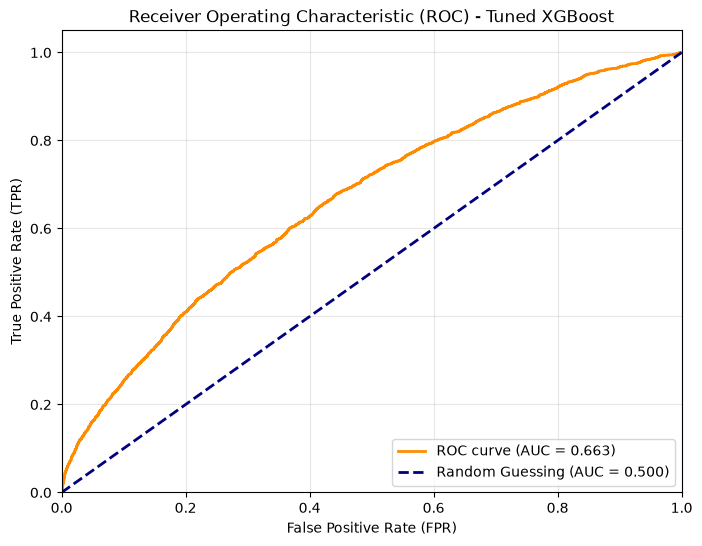

In [39]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Ensure you have the predicted probabilities for the positive class (Readmitted <30)
# If you just ran the Optuna block, use y_proba_tuned. 
# If you are using the baseline model, use y_proba.
# Here we default to y_proba from the standard model:
try:
    probabilities = y_proba_tuned 
    model_name = "Tuned XGBoost"
except NameError:
    probabilities = y_proba
    model_name = "Baseline XGBoost"

# 2. Calculate the ROC-AUC Score
roc_auc = roc_auc_score(y_test, probabilities)
print(f"{model_name} ROC-AUC Score: {roc_auc:.4f}")

# 3. Calculate the curve coordinates (False Positive Rate, True Positive Rate, Thresholds)
fpr, tpr, thresholds = roc_curve(y_test, probabilities)

# 4. Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing (AUC = 0.500)')

# Formatting the plot
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title(f'Receiver Operating Characteristic (ROC) - {model_name}')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()
